<a href="https://colab.research.google.com/github/MengOonLee/MachineLearning/blob/main/Courses/Statistics/MonteCarloSimulations/ESG_CO2e.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

np.random.seed(42)

# 1. Load or generate sample 2025 & 2026 dataset matching your exact schema
# (Replace this block with: df = pd.read_csv('your_travel_data.csv'))
n_rows = 2000
years_col = np.random.choice([2025, 2026], size=n_rows, p=[0.48, 0.52])
class_col = np.where(
    years_col == 2025,
    np.random.choice(['Business', 'Coach'], size=n_rows, p=[0.35, 0.65]),
    np.random.choice(['Business', 'Coach'], size=n_rows, p=[0.30, 0.70])
)

km_col = np.random.lognormal(mean=7.5, sigma=0.6, size=n_rows)
amount_col = km_col * np.where(class_col == 'Business', np.random.normal(0.55, 0.05, n_rows), np.random.normal(0.18, 0.03, n_rows))
co2_col = km_col * np.where(class_col == 'Business', np.random.normal(0.00042, 0.00003, n_rows), np.random.normal(0.00014, 0.00002, n_rows))

df = pd.DataFrame({
    'Employee': [f'EMP_{i%150:03d}' for i in range(n_rows)],
    'Travel Date': pd.to_datetime(years_col.astype(str) + '-06-15'),
    'Year': years_col,
    'Class': class_col,
    'KM': km_col,
    'Amount': amount_col,
    'CO2e': co2_col
})

df['Class'] = df['Class'].str.strip().str.title()

# 2. Historical Annual Summary & Target Threshold (70% of 2025 CO2e)
annual_summary = df.groupby('Year').agg(
    Total_Trips=('Employee', 'count'),
    Total_Budget=('Amount', 'sum'),
    Total_CO2e=('CO2e', 'sum')
)

co2_2025 = annual_summary.loc[2025, 'Total_CO2e']
budget_2026 = annual_summary.loc[2026, 'Total_Budget']
target_co2_cap = 0.70 * co2_2025

# 3. Inflation-adjust 2025 ticket prices to 2026 baseline levels
avg_cost_2025 = df[df['Year'] == 2025]['Amount'].mean()
avg_cost_2026 = df[df['Year'] == 2026]['Amount'].mean()
inflation_factor = avg_cost_2026 / avg_cost_2025

df['Adj_Amount'] = np.where(df['Year'] == 2025, df['Amount'] * inflation_factor, df['Amount'])

# 4. Calculate Cost & CO2e Ratios for Downgrading Business -> Coach
avg_biz_cost = df[df['Class'] == 'Business']['Adj_Amount'].mean()
avg_coach_cost = df[df['Class'] == 'Coach']['Adj_Amount'].mean()
downgrade_cost_ratio = avg_coach_cost / avg_biz_cost

avg_biz_co2 = df[df['Class'] == 'Business']['CO2e'].mean()
avg_coach_co2 = df[df['Class'] == 'Coach']['CO2e'].mean()
downgrade_co2_ratio = avg_coach_co2 / avg_biz_co2

print(annual_summary)
print(f"\n2025 Baseline CO2e: {co2_2025:.2f} tonnes")
print(f"2027–2030 Target Cap (70%): {target_co2_cap:.2f} tonnes")

      Total_Trips   Total_Budget  Total_CO2e
Year                                        
2025          944  637096.773381  496.807083
2026         1056  617637.707880  471.942639

2025 Baseline CO2e: 496.81 tonnes
2027–2030 Target Cap (70%): 347.76 tonnes


In [ ]:
n_sims = 5_000
forecast_years = [2027, 2028, 2029, 2030]
n_years = len(forecast_years)

# 1. Fuel Price Index & Pass-Through Elasticity (Policy 1 driver)
fuel_shocks = np.random.normal(loc=0.04, scale=0.07, size=(n_sims, n_years))
fuel_index = np.cumprod(1 + fuel_shocks, axis=1)
fuel_elasticity = np.random.triangular(left=0.30, mode=0.50, right=0.80, size=(n_sims, n_years))
ticket_multiplier = 1 + fuel_elasticity * (fuel_index - 1)

# 2. Policy 2: Business-to-Coach Incentive Conversion Rate (Beta distribution)
# Models the % of Business trips converted to Coach (up to 70% max adoption)
incentive_adoption = np.random.beta(a=4, b=2, size=(n_sims, n_years))
effective_conversion_rate = 0.70 * incentive_adoption

# 3. Policy 3: Annual Travel Budget Cut (% reduction from 2026 spend)
budget_cut_pct = np.random.uniform(low=0.05, high=0.22, size=(n_sims, n_years))
available_budget = budget_2026 * (1 - budget_cut_pct)

In [ ]:
# Extract NumPy arrays for fast sampling
pool_amounts = df['Adj_Amount'].to_numpy()
pool_co2 = df['CO2e'].to_numpy()
pool_is_biz = (df['Class'] == 'Business').to_numpy()
pool_size = len(df)

# Upper bound on candidate trips drawn per year (ensures cumulative spend exceeds budget)
max_candidate_trips = int(annual_summary['Total_Trips'].max() * 1.8)

sim_annual_co2 = np.zeros((n_sims, n_years))
sim_annual_trips = np.zeros((n_sims, n_years))

for yr_idx in range(n_years):
    for sim in range(n_sims):
        # 1. Random bootstrap draw with replacement from 2025-2026 trips
        draw_idx = np.random.randint(0, pool_size, size=max_candidate_trips)
        amounts = pool_amounts[draw_idx].copy()
        co2s = pool_co2[draw_idx].copy()
        is_biz = pool_is_biz[draw_idx]

        # 2. Apply Policy 2: Convert a random subset of Business trips to Coach
        downgrade_mask = is_biz & (np.random.rand(max_candidate_trips) < effective_conversion_rate[sim, yr_idx])
        amounts[downgrade_mask] *= downgrade_cost_ratio
        co2s[downgrade_mask] *= downgrade_co2_ratio

        # 3. Apply Policy 1: Increase ticket costs due to fuel price changes
        amounts *= ticket_multiplier[sim, yr_idx]

        # 4. Apply Policy 1 & 3: Stop booking once cumulative spend hits Available Budget
        cum_spend = np.cumsum(amounts)
        cutoff_idx = np.searchsorted(cum_spend, available_budget[sim, yr_idx])

        sim_annual_co2[sim, yr_idx] = co2s[:cutoff_idx].sum()
        sim_annual_trips[sim, yr_idx] = cutoff_idx

# Calculate Compliance Probabilities
yearly_pass_rate = np.mean(sim_annual_co2 <= target_co2_cap, axis=0) * 100
full_period_pass_rate = np.mean(np.all(sim_annual_co2 <= target_co2_cap, axis=1)) * 100

print("\n--- Simulation Results ---")
for i, yr in enumerate(forecast_years):
    print(f"{yr} Probability of Meeting 70% Cap: {yearly_pass_rate[i]:.1f}% (Median CO2e: {np.median(sim_annual_co2[:, i]):.1f}t)")
print(f"All Years (2027–2030) Compliance Probability: {full_period_pass_rate:.1f}%")


--- Simulation Results ---
2027 Probability of Meeting 70% Cap: 0.0% (Median CO2e: 434.7t)
2028 Probability of Meeting 70% Cap: 0.5% (Median CO2e: 426.7t)
2029 Probability of Meeting 70% Cap: 2.4% (Median CO2e: 416.7t)
2030 Probability of Meeting 70% Cap: 5.5% (Median CO2e: 408.4t)
All Years (2027–2030) Compliance Probability: 0.0%


In [ ]:
cumulative_co2 = np.sum(sim_annual_co2, axis=1)

driver_matrix = {
    'Travel Budget Cut (%)': np.mean(budget_cut_pct, axis=1),
    'Business-to-Coach Switch': np.mean(effective_conversion_rate, axis=1),
    'Fuel Price Growth': np.mean(fuel_index, axis=1),
    'Fuel-to-Ticket Elasticity': np.mean(fuel_elasticity, axis=1)
}

sensitivity_scores = {
    name: spearmanr(vals, cumulative_co2)[0]
    for name, vals in driver_matrix.items()
}

sorted_sensitivity = dict(sorted(sensitivity_scores.items(), key=lambda x: abs(x[1])))


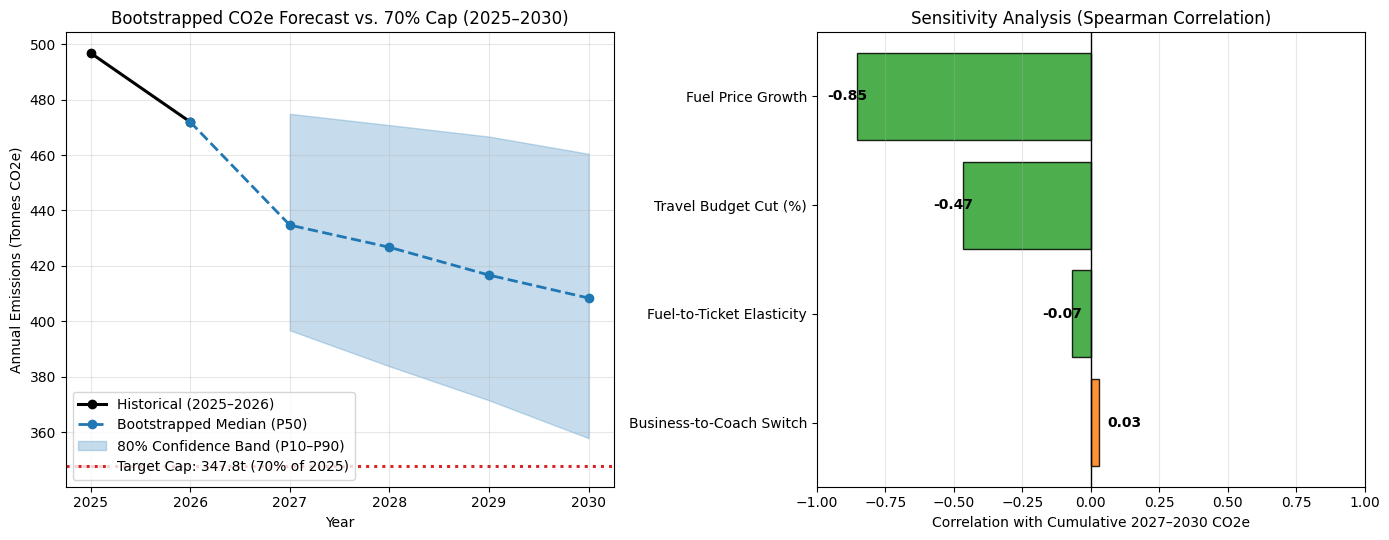

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# --- Left Panel: Emissions Trajectory Fan Chart ---
hist_years = [2025, 2026]
hist_co2 = annual_summary['Total_CO2e'].tolist()

p10 = np.percentile(sim_annual_co2, 10, axis=0)
p50 = np.percentile(sim_annual_co2, 50, axis=0)
p90 = np.percentile(sim_annual_co2, 90, axis=0)

ax1.plot(hist_years, hist_co2, color='black', marker='o', linewidth=2.2, label='Historical (2025–2026)')
ax1.plot([2026] + forecast_years, [hist_co2[-1]] + list(p50),
         color='#1f77b4', linestyle='--', marker='o', linewidth=2, label='Bootstrapped Median (P50)')
ax1.fill_between(forecast_years, p10, p90, color='#1f77b4', alpha=0.25, label='80% Confidence Band (P10–P90)')

ax1.axhline(target_co2_cap, color='#d62728', linestyle=':', linewidth=2.2,
            label=f'Target Cap: {target_co2_cap:.1f}t (70% of 2025)')

ax1.set_title('Bootstrapped CO2e Forecast vs. 70% Cap (2025–2030)')
ax1.set_xlabel('Year')
ax1.set_ylabel('Annual Emissions (Tonnes CO2e)')
ax1.set_xticks(hist_years + forecast_years)
ax1.grid(True, alpha=0.3)
ax1.legend(loc='lower left')

# --- Right Panel: Sensitivity Tornado Chart ---
names = list(sorted_sensitivity.keys())
corrs = list(sorted_sensitivity.values())
bar_colors = ['#2ca02c' if c < 0 else '#ff7f0e' for c in corrs]

bars = ax2.barh(names, corrs, color=bar_colors, edgecolor='black', alpha=0.85)
ax2.axvline(0, color='black', linewidth=1)
ax2.set_xlim(-1.0, 1.0)
ax2.set_title('Sensitivity Analysis (Spearman Correlation)')
ax2.set_xlabel('Correlation with Cumulative 2027–2030 CO2e')
ax2.grid(True, axis='x', alpha=0.3)

for bar in bars:
    w = bar.get_width()
    offset = -0.11 if w < 0 else 0.03
    ax2.text(w + offset, bar.get_y() + bar.get_height()/2, f'{w:.2f}', va='center', fontweight='bold')

plt.tight_layout()
plt.show()
